In [ ]:
import pandas as pd

In [ ]:
df_prod_review = pd.read_csv('https://raw.githubusercontent.com/aakashgoel12/blogs/master/input/product_review_sentiment.csv',\
                      encoding='latin-1')
text = df_prod_review['Review']
text_list =  [i.split() for i in text]
print(len(text_list))

26873
[['awesome', 'love', 'album', 'good', 'hip', 'hop', 'side', 'current', 'pop', 'sound', 'hype', 'listen', 'everyday', 'gym', 'give', 'star', 'rating', 'way', 'metaphor', 'crazy'], ['good', 'good', 'flavor', 'review', 'collect', 'part', 'promotion'], ['good', 'good', 'flavor'], ['disappoint', 'read', 'review', 'look', 'buy', 'one', 'couple', 'lubricant', 'ultimately', 'disappointed', 'didnt', 'even', 'live', 'review', 'read', 'starter', 'neither', 'boyfriend', 'could', 'notice', 'sort', 'enhanced', 'captivate', 'sensation', 'notice', 'however', 'messy', 'consistency', 'reminiscent', 'liquidy', 'vaseline', 'difficult', 'clean', 'pleasant', 'especially', 'since', 'lack', 'captivate', 'sensation', 'expect', 'im', 'disappoint', 'pay', 'much', 'lube', 'wont', 'use', 'could', 'use', 'normal', 'personal', 'lubricant', 'less', 'money', 'less', 'mess'], ['irritation', 'husband', 'buy', 'gel', 'us', 'gel', 'caused', 'irritation', 'felt', 'like', 'burn', 'skin', 'wouldnt', 'recommend', 'gel']

In [ ]:
import gensim
# Create bigram and trigram Models
from gensim.models import Phrases
# Add bigrams and trigrams to docs, minimum count 10 means only that appear 10 times or more.
bigram = Phrases(text_list, min_count=10)
trigram = Phrases(bigram[text_list])
for idx in range(len(text_list)):
    for token in bigram[text_list[idx]]:
        if '_' in token:
            # Token is a bigram, add to document.
            text_list[idx].append(token)
    for token in trigram[text_list[idx]]:
        if '_' in token:
            # Token is a trigram, add to document.
            text_list[idx].append(token)

In [ ]:
from gensim import corpora, models
# Create a dictionary representation of the documents.
dictionary = corpora.Dictionary(text_list)
dictionary.filter_extremes(no_below=5, no_above=0.2)
# Keep terms appearing in at least 5 documents and no more than 20% of the documents
print(dictionary)

Dictionary<5848 unique tokens: ['album', 'awesome', 'crazy', 'current', 'everyday']...>


In [ ]:
# Build corpus
# Converting list of documents (corpus) into Document Term Matrix using dictionary prepared above.
doc_term_matrix = [dictionary.doc2bow(doc) for doc in text_list]
# The function doc2bow converts document (a list of words) into the bag-of-words format
print(len(doc_term_matrix))
print(doc_term_matrix[100])
tfidf = models.TfidfModel(doc_term_matrix) # Build TF-IDF model
corpus_tfidf = tfidf[doc_term_matrix]

26873
[(67, 2), (196, 1), (221, 1), (252, 2), (399, 1), (453, 1), (647, 1), (649, 1), (650, 1), (651, 1), (652, 3)]


In [ ]:
from gensim.models.coherencemodel import CoherenceModel
from gensim.models.ldamodel import LdaModel
from gensim.corpora.dictionary import Dictionary
# Function to compute coherence values
def compute_coherence_values(dictionary, corpus, texts, limit, start, step):
    coherence_values = []
    model_list = []
    for num_topics in range(start, limit, step):
        model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=num_topics, iterations=100, random_state=42)
        model_list.append(model)
        coherencemodel = CoherenceModel(model=model, texts=texts, dictionary=dictionary, coherence='c_v')
        coherence_values.append(coherencemodel.get_coherence())

    return model_list, coherence_values

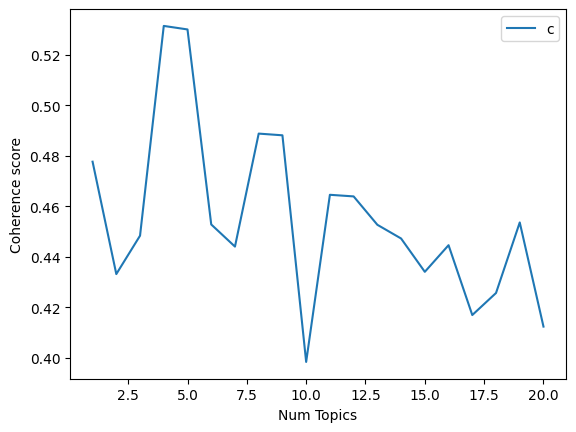

In [ ]:
start=1
limit=21
step=1
model_list, coherence_values = compute_coherence_values(dictionary, corpus=corpus_tfidf,
                                                        texts=text_list, start=start, limit=limit, step=step)
# Show graphs
import matplotlib.pyplot as plt
x = range(start, limit, step)
plt.plot(x, coherence_values)
plt.xlabel("Num Topics")
plt.ylabel("Coherence score")
plt.legend(("coherence_values"), loc='best')
plt.show()

In [ ]:
# Print the coherence scores
for m, cv in zip(x, coherence_values):
    print("Num Topics =", m, " has Coherence Value of", round(cv, 6))

Num Topics = 1  has Coherence Value of 0.477619
Num Topics = 2  has Coherence Value of 0.433149
Num Topics = 3  has Coherence Value of 0.448341
Num Topics = 4  has Coherence Value of 0.531343
Num Topics = 5  has Coherence Value of 0.52995
Num Topics = 6  has Coherence Value of 0.452783
Num Topics = 7  has Coherence Value of 0.444022
Num Topics = 8  has Coherence Value of 0.488735
Num Topics = 9  has Coherence Value of 0.48806
Num Topics = 10  has Coherence Value of 0.398389
Num Topics = 11  has Coherence Value of 0.464521
Num Topics = 12  has Coherence Value of 0.463883
Num Topics = 13  has Coherence Value of 0.452655
Num Topics = 14  has Coherence Value of 0.447226
Num Topics = 15  has Coherence Value of 0.434041
Num Topics = 16  has Coherence Value of 0.444579
Num Topics = 17  has Coherence Value of 0.416939
Num Topics = 18  has Coherence Value of 0.425664
Num Topics = 19  has Coherence Value of 0.453578
Num Topics = 20  has Coherence Value of 0.412365


In [ ]:
# Find the highest coherence index
best_index = coherence_values.index(max(coherence_values))
final_model = model_list[best_index]
best_num_topics = 1 + best_index  # karena start=1, step=1

print("Best number of topics:", best_num_topics)
print("Best coherence score:", coherence_values[best_index])

# Save the best model and data needed
final_model.save("lda_model.model")
dictionary.save("lda_dictionary.dict")
corpora.MmCorpus.serialize("lda_corpus.mm", corpus_tfidf)

Best number of topics: 4
Best coherence score: 0.5313430563821293


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Save to Drive
final_model.save('/content/drive/MyDrive/lda_model.model')
dictionary.save('/content/drive/MyDrive/lda_dictionary.dict')
corpora.MmCorpus.serialize('/content/drive/MyDrive/lda_corpus.mm', corpus_tfidf)